In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

En un edificio de oficinas, las actividades de estructura y cerramiento del cuadro adjunto pueden ejecutarse **in situ** (el plan) o con **elementos prefabricados** en una fábrica a **250 km**. El cuadro recoge las prelaciones, las duraciones in situ (semanas), los operarios de cada actividad, las semanas que se ahorran en cada actividad prefabricándola (`reduccion_prefabricado`) y las toneladas de residuo que cada actividad genera en la obra si se ejecuta in situ (`residuos_t`); prefabricada, genera en la obra el 20% (el resto se produce y se recicla en la fábrica).

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, resources, reduccion_prefabricado, residuos_t
    ('A'     , '---'      , 3       , 2        , 1                     , 37        ),
    ('B'     , '---'      , 1       , 2        , 0                     , 0         ),
    ('C'     , 'A'        , 3       , 3        , 1                     , 11        ),
    ('D'     , 'C'        , 2       , 1        , 0                     , 0         ),
    ('E'     , 'B,C'      , 1       , 4        , 0                     , 0         ),
    ('F'     , 'B,C'      , 4       , 3        , 0                     , 0         ),
    ('G'     , 'E,F'      , 7       , 1        , 0                     , 0         ),
    ('H'     , 'D,G'      , 4       , 3        , 1                     , 23        ),
], columns=['activity', 'predecessor', 'duration', 'resources', 'reduccion_prefabricado', 'residuos_t']).set_index('activity')
datos_enunciado

,predecessor,duration,resources,reduccion_prefabricado,residuos_t
activity,,,,,
A,---,3,2,1,37
B,---,1,2,0,0
C,A,3,3,1,11
D,C,2,1,0,0
E,"B,C",1,4,0,0
F,"B,C",4,3,0,0
G,"E,F",7,1,0,0
H,"D,G",4,3,1,23


Datos: los elementos prefabricados pesan 230 t y llegan por carretera (0.12 €/t·km, 0.1 kg CO₂/t·km); el material prefabricado cuesta 20 k€ más que el in situ; cada semana de obra cuesta 10 k€ (instalaciones, grúa, equipo técnico) y emite 3.0 t CO₂ (gasóleo y electricidad); el residuo de obra cuesta 45 €/t de gestión y viaja 25 km hasta el gestor. Precio sombra del carbono de la organización: 150 €/t.

> **De: Director técnico**
> In situ, como siempre. La prefabricación trae 230 toneladas de hormigón en camiones desde 250 km, que es lo contrario de sostenible, y nos cobran 20 k€ más. Lo que ahorremos en semanas de obra no es de este presupuesto, y los residuos los gestiona el gestor, para eso se le paga.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 20 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **S2 — Externalidad internalizada.** Cuando la organización ha fijado un precio para una externalidad (precio sombra del carbono, canon, tasa), toda decisión de planificación —comprimir, comprar, diseñar— se compara por el coste total: coste del proyecto más el valor de la externalidad a ese precio. Con el precio fijado, la alternativa correcta es la de menor coste total, y comprar compensaciones a un precio inferior no cambia la cuenta. *(cf. PMBOK 8 §3.7 (estrategias para abordar las externalidades); LCSP art. 148.2 (externalidades medioambientales monetizables); precio sombra del carbono del BEI.)*
- **S6 — Alcances de las emisiones.** Las emisiones de un proyecto se clasifican por quién controla la fuente: alcance 1, combustión en fuentes propias o controladas (maquinaria y vehículos propios, generadores); alcance 2, electricidad comprada; alcance 3, el resto de la cadena (subcontratas, transporte ajeno, materiales comprados, viajes). A qué alcance pertenece cada fuente tiene respuesta determinada, y el alcance 3 no deja de contar por ser ajeno. *(cf. GHG Protocol, estándar corporativo; UNE-EN ISO 14064-1; registro de huella de carbono del MITECO (RD 163/2014).)*
- **S8 — Jerarquía de residuos y separación en origen.** El orden es prevención, preparación para la reutilización, reciclado, otra valorización y, en último lugar, eliminación. Los residuos de construcción y demolición no peligrosos se clasifican, preferentemente en la obra, en al menos seis fracciones (madera, minerales, metales, vidrio, plástico y yeso) y la demolición es selectiva, previo estudio de las cantidades de cada fracción. Mezclarlo todo en un contenedor que va a vertedero es elegir el último escalón e incumplir la obligación de clasificar. *(cf. Ley 7/2022 de residuos y suelos contaminados, arts. 8 y 30; RD 105/2008 (estudio y plan de gestión de RCD).)*
- **S4 — Orientación temporal: el proyecto responde de sus resultados.** La dirección del proyecto puede orientarse al proceso (hasta la entrega), a los entregables (su vida útil) o a los resultados (lo que dejan a la comunidad y al futuro). Un caso de negocio que termina en la puesta en servicio deja fuera costes y beneficios que pertenecen al proyecto (operación, desmantelamiento, residuos finales); si una obligación futura es consecuencia de la inversión, su valor actual forma parte del coste. *(cf. PMBOK 8 §3.7.1 (figura 3-8); Plan General de Contabilidad, norma de valoración 2.ª (obligaciones de desmantelamiento).)*
- **Norma o dato de referencia — factores de emisión que usa el enunciado: gasóleo 2,47 kg CO₂ por litro; electricidad de red 0,15 kg CO₂ por kWh (mix de comercializadora genérico); transporte por carretera 0,10 y marítimo 0,015 kg CO₂ por tonelada y kilómetro. Son valores orientativos: en un caso real se toman los factores oficiales del año** *(calculadora de huella de carbono del MITECO (factores anuales); CNMC (mix de comercializadoras).)*
- **Norma o dato de referencia — alcance 1: emisiones directas de fuentes propias o controladas (combustible de maquinaria y vehículos propios, generadores en obra); alcance 2: emisiones indirectas de la electricidad comprada; alcance 3: las demás emisiones indirectas de la cadena de valor (materiales comprados, transporte contratado, subcontratas, residuos, viajes)** *(GHG Protocol, Corporate Accounting and Reporting Standard; UNE-EN ISO 14064-1.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Calcule la duración del proyecto in situ y prefabricado, las operario-semanas en obra de cada opción (diagrama de cargas) y las toneladas de residuo que se generan en la obra en cada caso.  "
pregunta_2 = "2. (A) Calcule el coste (material, semanas de obra, transporte, gestión de residuos) y las emisiones (semanas de obra, transporte de los prefabricados, transporte del residuo) de cada opción, y el coste total al precio sombra. ¿Pesan más los camiones de la fábrica o las semanas de obra?  "
pregunta_3 = "3. (B) Según los criterios de referencia, ¿es correcto decir que la prefabricación «es lo contrario de sostenible por los camiones»? Clasifique el transporte de los prefabricados por su alcance y el residuo evitado por su escalón en la jerarquía, y decida por el coste total. ¿«Lo que ahorremos en semanas no es de este presupuesto» cambia la cuenta?  "
pregunta_4 = "4. (C) ¿Qué propone al director técnico y a la dirección? Aplique la rúbrica de la lección.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Calcule la duración del proyecto in situ y prefabricado, las operario-semanas en obra de cada opción (diagrama de cargas) y las toneladas de residuo que se generan en la obra en cada caso.  

2. (A) Calcule el coste (material, semanas de obra, transporte, gestión de residuos) y las emisiones (semanas de obra, transporte de los prefabricados, transporte del residuo) de cada opción, y el coste total al precio sombra. ¿Pesan más los camiones de la fábrica o las semanas de obra?  

3. (B) Según los criterios de referencia, ¿es correcto decir que la prefabricación «es lo contrario de sostenible por los camiones»? Clasifique el transporte de los prefabricados por su alcance y el residuo evitado por su escalón en la jerarquía, y decida por el coste total. ¿«Lo que ahorremos en semanas no es de este presupuesto» cambia la cuenta?  

4. (C) ¿Qué propone al director técnico y a la dirección? Aplique la rúbrica de la lección.  

# Resolución

In [6]:
peso_prefabricados, km_fabrica, extra_material, coste_semana, emisiones_semana, fraccion_residuo_pref, precio_sombra = 230, 250, 20, 10, 3.0, 0.2, 150
coste_camion, factor_camion, coste_gestion_residuo, km_gestor = 0.12, 0.1, 45, 25
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))
prefabricadas = sorted(datos_proyecto.index[datos_proyecto['reduccion_prefabricado'] > 0])
datos_pref = datos_proyecto.copy()
datos_pref['duration'] = datos_proyecto['duration'] - datos_proyecto['reduccion_prefabricado']
duracion_pref = int(proyecto.duration(datos_pref['duration']))

Cálculo de los tiempos tempranos y tardíos de los sucesos y de las holguras totales paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

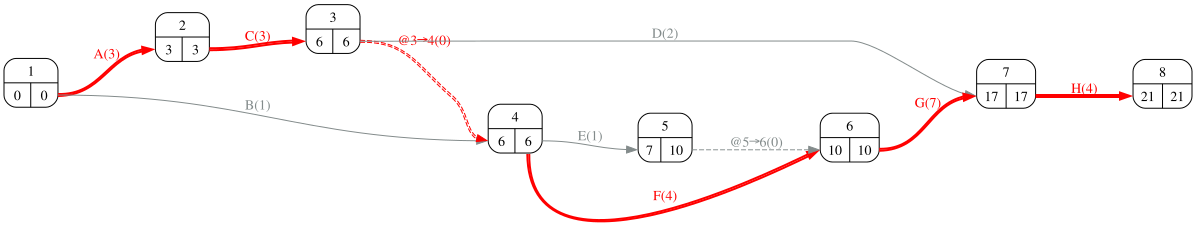

In [8]:
#| fig-cap: "Grafo PERT con las duraciones in situ"
#| label: fig-pert
proyecto.display_pert_pasos(datos_proyecto['duration'])

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Calcule la duración del proyecto in situ y prefabricado, las operario-semanas en obra de cada opción (diagrama de cargas) y las toneladas de residuo que se generan en la obra en cada caso.  

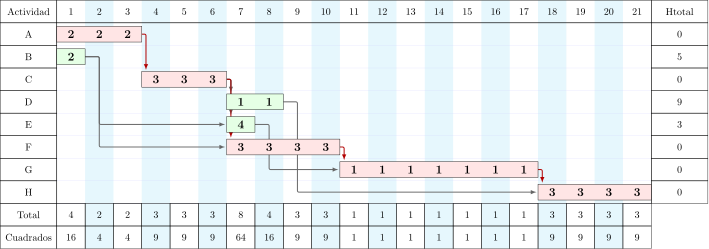

In [10]:
#| fig-cap: "Gantt y carga de operarios: ejecución in situ"
#| label: fig-ganttInSitu
gantt_in, dibujo_in = proyecto.copy().gantt_cargas(datos_proyecto.copy(), 'duration', 'resources', report=False, tikz=True, params=GANTT_PARAMS)
pinta_tikz(dibujo_in)

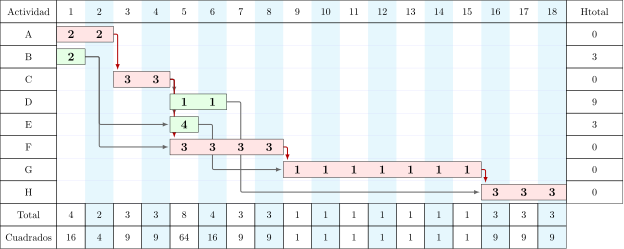

In [11]:
#| fig-cap: "Gantt y carga de operarios: con prefabricados"
#| label: fig-ganttPref
gantt_pref, dibujo_pref = proyecto.copy().gantt_cargas(datos_pref.copy(), 'duration', 'resources', report=False, tikz=True, params=GANTT_PARAMS)
pinta_tikz(dibujo_pref)

In [12]:
op_in = float(gantt_in.data.loc['Total'].drop('H_total').astype(float).sum())
op_pref = float(gantt_pref.data.loc['Total'].drop('H_total').astype(float).sum())
residuo_in = float(datos_proyecto['residuos_t'].sum()); residuo_pref = residuo_in * fraccion_residuo_pref
camino_pref = ' / '.join('–'.join(r) for r in proyecto.critical_path(datos_pref['duration']).values())
resumen = pd.DataFrame({'in situ': [duracion, op_in, residuo_in], 'prefabricado': [duracion_pref, op_pref, residuo_pref]},
                       index=['duración (semanas)', 'operario-semanas en obra', 'residuo en obra (t)'])
display(resumen.round(1))
Markdown(f'''Prefabricar acorta el proyecto de {duracion} a **{duracion_pref}** semanas (ruta crítica {camino_pref}), quita {op_in - op_pref:.0f} operario-semanas de la obra y evita {residuo_in - residuo_pref:.0f} t de residuo en ella.''')

,in situ,prefabricado
duración (semanas),21.0,18.0
operario-semanas en obra,54.0,46.0
residuo en obra (t),71.0,14.2


Prefabricar acorta el proyecto de 21 a **18** semanas (ruta crítica A–C–F–G–H), quita 8 operario-semanas de la obra y evita 57 t de residuo en ella.

## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. (A) Calcule el coste (material, semanas de obra, transporte, gestión de residuos) y las emisiones (semanas de obra, transporte de los prefabricados, transporte del residuo) de cada opción, y el coste total al precio sombra. ¿Pesan más los camiones de la fábrica o las semanas de obra?  

In [14]:
#| tbl-cap: "Coste y emisiones de cada opción"
#| label: tbl-opciones
def opcion(semanas, residuo, transporte_t_km, extra):
    coste = pd.Series({'material prefabricado (k€)': extra, 'semanas de obra (k€)': semanas * coste_semana,
                       'transporte de prefabricados (k€)': transporte_t_km * coste_camion / 1000,
                       'gestión del residuo (k€)': residuo * coste_gestion_residuo / 1000})
    emisiones = pd.Series({'semanas de obra (t CO₂)': semanas * emisiones_semana,
                           'transporte de prefabricados, alcance 3 (t CO₂)': transporte_t_km * factor_camion / 1000,
                           'transporte del residuo, alcance 3 (t CO₂)': residuo * km_gestor * factor_camion / 1000})
    s = pd.concat([coste, emisiones])
    s['coste monetario (k€)'] = coste.sum(); s['emisiones (t CO₂)'] = emisiones.sum()
    s['coste total al precio sombra (k€)'] = s['coste monetario (k€)'] + s['emisiones (t CO₂)'] * precio_sombra / 1000
    return s
comparacion = pd.DataFrame({'in situ': opcion(duracion, residuo_in, 0, 0),
                            'prefabricado': opcion(duracion_pref, residuo_pref, peso_prefabricados * km_fabrica, extra_material)})
display(comparacion.round(2))
em_camiones = comparacion.loc['transporte de prefabricados, alcance 3 (t CO₂)', 'prefabricado']
em_semanas = comparacion.loc['semanas de obra (t CO₂)', 'in situ'] - comparacion.loc['semanas de obra (t CO₂)', 'prefabricado']
Markdown(f'''Los camiones de la fábrica emiten {em_camiones:.1f} t; las {duracion - duracion_pref} semanas de obra que se ahorran, {em_semanas:.1f} t. En total, prefabricar ''' + ('emite menos' if comparacion.loc['emisiones (t CO₂)', 'prefabricado'] < comparacion.loc['emisiones (t CO₂)', 'in situ'] else 'emite más') + f''' ({comparacion.loc['emisiones (t CO₂)', 'prefabricado']:.1f} frente a {comparacion.loc['emisiones (t CO₂)', 'in situ']:.1f} t) y cuesta ''' + ('**' + f'''{abs(comparacion.loc['coste total al precio sombra (k€)', 'in situ'] - comparacion.loc['coste total al precio sombra (k€)', 'prefabricado']):.1f} k€ ''' + ('menos' if comparacion.loc['coste total al precio sombra (k€)', 'prefabricado'] < comparacion.loc['coste total al precio sombra (k€)', 'in situ'] else 'más') + '**') + f''' al precio sombra ({abs(comparacion.loc['coste monetario (k€)', 'in situ'] - comparacion.loc['coste monetario (k€)', 'prefabricado']):.1f} k€ ''' + ('menos' if comparacion.loc['coste monetario (k€)', 'prefabricado'] < comparacion.loc['coste monetario (k€)', 'in situ'] else 'más') + ' en dinero).')

,in situ,prefabricado
material prefabricado (k€),0.00,20.00
semanas de obra (k€),210.00,180.00
transporte de prefabricados (k€),0.00,6.90
gestión del residuo (k€),3.20,0.64
semanas de obra (t CO₂),63.00,54.00
"transporte de prefabricados, alcance 3 (t CO₂)",0.00,5.75
"transporte del residuo, alcance 3 (t CO₂)",0.18,0.04
coste monetario (k€),213.20,207.54
emisiones (t CO₂),63.18,59.79
coste total al precio sombra (k€),222.67,216.51


Los camiones de la fábrica emiten 5.8 t; las 3 semanas de obra que se ahorran, 9.0 t. En total, prefabricar emite menos (59.8 frente a 63.2 t) y cuesta **6.2 k€ menos** al precio sombra (5.7 k€ menos en dinero).

## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. (B) Según los criterios de referencia, ¿es correcto decir que la prefabricación «es lo contrario de sostenible por los camiones»? Clasifique el transporte de los prefabricados por su alcance y el residuo evitado por su escalón en la jerarquía, y decida por el coste total. ¿«Lo que ahorremos en semanas no es de este presupuesto» cambia la cuenta?  

**S6.** El transporte de los prefabricados por un transportista contratado es **alcance 3** del proyecto, y cuenta: 5.8 t. Pero también cuentan las semanas de obra que se ahorran (3 × 3.0 t) y el residuo que no se genera, y «lo contrario de sostenible» es una afirmación sobre una columna de la tabla, no sobre la tabla. **S8.** Las 57 t de residuo que no llegan a producirse en la obra son **prevención**, el primer escalón de la jerarquía; «los gestiona el gestor» es el último. **S2.** Con el precio sombra la decisión es el coste total: **prefabricado** (216.5 k€ frente a 222.7 in situ); también es más barato en dinero. **S4.** «Lo que ahorremos en semanas no es de este presupuesto» es la orientación al proceso: las 3 semanas de instalaciones, grúa y equipo son consecuencia de la decisión que se toma ahora, las pague quien las pague; sacarlas de la cuenta es la misma trampa que el consumo del equipo barato (caso del ciclo de vida).

In [16]:
preguntas_test = [
    ('El transporte de los elementos prefabricados por un transportista contratado es, para el proyecto…', ['alcance 3', 'alcance 1', 'alcance 2', 'no se contabiliza por ser del proveedor'],
     'S6: transporte contratado.'),
    ('Generar menos residuo en la obra porque los elementos llegan fabricados es, en la jerarquía de residuos…', ['prevención, el primer escalón', 'reciclado', 'otra valorización', 'eliminación'],
     'S8: el residuo que no se produce.'),
    ('Entre dos sistemas constructivos, con un precio sombra del carbono fijado, se elige…', ['el de menor coste total: material, transporte, semanas de obra y residuos, más las emisiones al precio sombra', 'el de menos camiones', 'el de menor precio de material', 'el que siempre se ha usado'],
     'S2: toda la tabla, no una columna.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Sostenibilidad 20 — prefabricación')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_sostenibilidad.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Sostenibilidad 20 — prefabricación

::Sostenibilidad 20 — prefabricación P1::El transporte de los elementos prefabricados por un transportista contratado es, para el proyecto… {=alcance 3 ~alcance 1 ~alcance 2 ~no se contabiliza por ser del proveedor ####S6: transporte contratado.}

::Sostenibilidad 20 — prefabricación P2::Generar menos residuo en la obra porque los elementos llegan fabricados es, en la jerarquía de residuos… {~eliminación =prevención, el primer escalón ~otra valorización ~reciclado ####S8: el residuo que no se produce.}

::Sostenibilidad 20 — prefabricación P3::Entre dos sistemas constructivos, con un precio sombra del carbono fijado, se elige… {~el que siempre se ha usado =el de menor coste total: material, transporte, semanas de obra y residuos, más las emisiones al precio sombra ~el de menos camiones ~el de menor precio de material ####S2: toda la tabla, no una columna.}



## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al director técnico y a la dirección? Aplique la rúbrica de la lección.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados, incluidos los que no están en la mesa (la comunidad, los trabajadores de la cadena, quien opere o desmantele lo construido, las generaciones siguientes) y qué pierde o gana cada uno con las cifras del bloque A; (2) formular al menos dos alternativas además de la propuesta, situándolas en la pirámide (compensar, restaurar, minimizar, evitar); (3) someter cada alternativa a tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería ante el inspector, el cliente o la prensa?) y ciclo de vida (¿quién paga el impacto y cuándo?)—; (4) decidir y redactar la comunicación con las cifras. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al director técnico: la tabla del apartado 2 entera, con los camiones en su fila y las semanas en la suya; y las condiciones para que el prefabricado funcione (plazo de fábrica, grúa dimensionada, tolerancias). A la dirección: la decisión con el coste total y la reducción de residuo (57 t) para el plan de gestión y la memoria. Prueba del ciclo de vida: ¿quién paga las 3 semanas de obra que no se ahorran, y en qué presupuesto aparecen?